# 回归模型

## 1.数据探索

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
import matplotlib_inline
from sklearn.metrics import mean_squared_error
diabetes = load_diabetes()
diabetes.keys()

dict_keys(['data', 'target', 'frame', 'DESCR', 'feature_names', 'data_filename', 'target_filename', 'data_module'])

In [2]:
diabetes['data'].shape

(442, 10)

In [3]:
print(diabetes['DESCR'])

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

## 2.线性回归预测与评估

In [4]:
X = diabetes['data']
y = diabetes['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 8)
diabetes_lr = LinearRegression()
diabetes_lr.fit(X_train, y_train)
y_predict = diabetes_lr.predict(X_test)

mse = mean_squared_error(y_test, y_predict)
print('均方误差:',mse)
print('coef_:{}'.format(diabetes_lr.coef_[:]))
print('intercept_:{}'.format(diabetes_lr.intercept_))

均方误差: 3108.0516308221804
coef_:[   11.51226671  -282.51443231   534.2084846    401.73037118
 -1043.90460259   634.92891045   186.43568421   204.94157943
   762.46336088    91.95399832]
intercept_:152.5625670974632


# 岭回归模型预测与评估

## 1.alpha=1.0时

In [5]:
from sklearn.linear_model import Ridge
diabetes_ridge = Ridge(alpha = 1.0)
diabetes_ridge.fit(X_train, y_train)
y_predict_1 = diabetes_ridge.predict(X_test)

mse_1 = mean_squared_error(y_test, y_predict)
print('均方误差：:',mse_1)
print('coef_:{}'.format(diabetes_ridge.coef_[:]))
print('intercept_:{}'.format(diabetes_ridge.intercept_))

均方误差：: 3108.0516308221804
coef_:[  36.82662813  -75.80807883  282.42734567  207.39238457   -1.46557355
  -27.81684598 -134.37462416   98.97793127  222.67324438  117.97352343]
intercept_:152.55358561069758


## 2.alpha=10时

In [6]:
from sklearn.linear_model import Ridge
diabetes_ridge10 = Ridge(alpha = 10)
diabetes_ridge10.fit(X_train, y_train)
y_predict_10 = diabetes_ridge10.predict(X_test)

mse_10 = mean_squared_error(y_test, y_predict_10)
print('均方误差：:',mse_10)
print('coef_:{}'.format(diabetes_ridge10.coef_[:]))
print('intercept_:{}'.format(diabetes_ridge10.intercept_))

均方误差：: 4817.250569249039
coef_:[ 15.08678995  -1.95860257  60.69907663  47.11820496  14.72340007
   9.87783455 -35.56018492  35.746079    54.27153373  37.42100763]
intercept_:152.75858723229436


## 3.alpha=0.1时

In [7]:
from sklearn.linear_model import Ridge
diabetes_ridge01 = Ridge(alpha = 0.1)
diabetes_ridge01.fit(X_train, y_train)
y_predict01 = diabetes_ridge01.predict(X_test)

mse_01 = mean_squared_error(y_test, y_predict01)
print('均方误差：:',mse_01)
print('coef_:{}'.format(diabetes_ridge01.coef_[:]))
print('intercept_:{}'.format(diabetes_ridge01.intercept_))

均方误差：: 3027.231204132918
coef_:[  24.77951665 -228.33361625  495.54897969  361.21202032 -109.82577405
  -78.32656519 -190.69880646  108.24278136  383.71663452  107.42973692]
intercept_:152.481009158938


# 套索回归模型

## 1.alpha=1时

In [8]:
from sklearn.linear_model import Lasso
lasso1 = Lasso(alpha=1)
lasso1.fit(X_train,y_train)
y_predict_lasso1 = lasso1.predict(X_test)

print('lasso.coef_:{}'.format(lasso1.coef_[:]))
print('lasso.intercept_:{}'.format(lasso1.intercept_))
mse_2 = mean_squared_error(y_test,y_predict_lasso1)
print('套索回归模型的均方误差：',mse_2)

lasso.coef_:[  0.          -0.         384.73866871  72.69163139   0.
   0.          -0.           0.         247.88294779   0.        ]
lasso.intercept_:152.6882652822777
套索回归模型的均方误差： 3646.8311517332627


## alpha = 10

In [9]:
from sklearn.linear_model import Lasso
lasso10 = Lasso(alpha=10)
lasso10.fit(X_train,y_train)
y_predict_lasso10 = lasso10.predict(X_test)

print('lasso.coef_:{}'.format(lasso10.coef_[:]))
print('lasso.intercept_:{}'.format(lasso10.intercept_))
mse_2 = mean_squared_error(y_test,y_predict_lasso10)
print('套索回归模型的均方误差：',mse_2)

lasso.coef_:[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
lasso.intercept_:152.8489425981873
套索回归模型的均方误差： 5756.765122576417


## alpha=0.1

In [10]:
from sklearn.linear_model import Lasso
lasso01 = Lasso(alpha=0.1)
lasso01.fit(X_train,y_train)
y_predict_lasso01 = lasso01.predict(X_test)

print('lasso.coef_:{}'.format(lasso01.coef_[:]))
print('lasso.intercept_:{}'.format(lasso01.intercept_))
mse_2 = mean_squared_error(y_test,y_predict_lasso01)
print('套索回归模型的均方误差：',mse_2)

lasso.coef_:[   0.         -181.40914131  537.72343885  355.19463978 -105.43063139
   -0.         -199.00271513    0.          440.24142661   48.26157674]
lasso.intercept_:152.43697494833327
套索回归模型的均方误差： 2989.5961816991025


# 7个结果展示

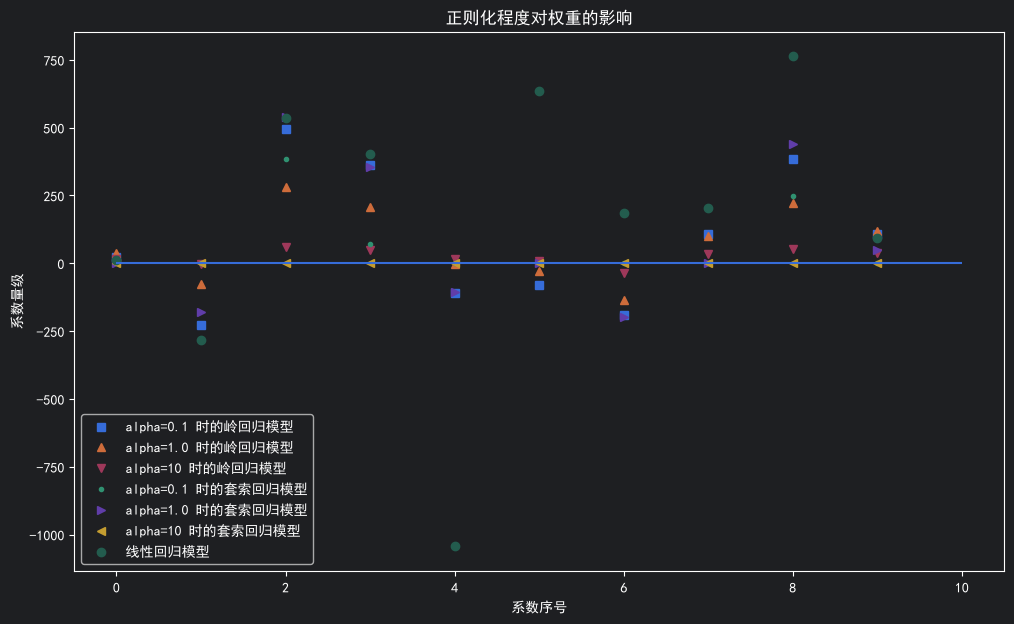

In [11]:
from sklearn.linear_model import Ridge,LinearRegression
from sklearn.datasets import load_diabetes
# 解决中文乱码
plt.rcParams['font.sans-serif'] = 'SimHei'
plt.rcParams['axes.unicode_minus'] = False
#创建画布
plt.figure(figsize=(12,7))
# 修改RC参数，来让其支持中文
plt.rcParams['font.sans-serif'] = 'SimHei'
plt.rcParams['axes.unicode_minus'] = False
#绘图
x = np.arange(0,10)
#alpha=0.1
plt.plot(x, diabetes_ridge01.coef_,'s',label='alpha=0.1 时的岭回归模型')
#alpha=1
plt.plot(x, diabetes_ridge.coef_,'^',label='alpha=1.0 时的岭回归模型')
# alpha=10
plt.plot(x, diabetes_ridge10.coef_,'v',label='alpha=10 时的岭回归模型')
#套索回归
x = np.arange(0,10)
#alpha=0.1
plt.plot(x, lasso1.coef_,'.',label='alpha=0.1 时的套索回归模型')
#alpha=1
plt.plot(x, lasso01.coef_,'>',label='alpha=1.0 时的套索回归模型')
# alpha=10
plt.plot(x, lasso10.coef_,'<',label='alpha=10 时的套索回归模型')
# 线性回归
plt.plot(x, diabetes_lr.coef_,'o',label='线性回归模型')
# 添加图例
plt.legend()
# 添加标题
plt.title("正则化程度对权重的影响")
plt.xlabel('系数序号')
plt.ylabel('系数量级')
plt.hlines(0,0,len(diabetes_lr.coef_))
plt.show()